In [2]:
from qiskit import *
import numpy as np
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, thermal_relaxation_error
import matplotlib.pyplot as plt
from qutip import Qobj, fidelity, tracedist, concurrence, qeye
import pandas as pd
import scienceplots


## Denifição Entanglement Bell's Inequality

In [3]:

# 1) Circuito: singlete + cadeia de SWAPs + rotações para medição
def bell_with_swaps(n=0, theta_a=0.0, theta_b=0.0):
    q0 = QuantumRegister(1, 'Alice')
    q1 = QuantumRegister(1, 'Bob')
    regs_q = [q0, q1]
    if n > 0:
        ext = QuantumRegister(n, 'ext')
        regs_q.append(ext)

    c = ClassicalRegister(2, 'c')  # só medimos Alice e Bob
    qc = QuantumCircuit(*regs_q, c, name=f'CHSH_swaps_{n}')

    # Estado singlete (|01> - |10>)/√2
    qc.x(q1[0])
    qc.h(q0[0])
    qc.cx(q0[0], q1[0])
    qc.z(q1[0])

    # Cadeia de SWAPs levando o qubit de Bob até o último ext
    if n > 0:
        qc.swap(q1[0], ext[0])
        for i in range(1, n):
            qc.swap(ext[i-1], ext[i])
        b_final = ext[n-1]
    else:
        b_final = q1[0]

    qc.barrier()

    # Rotações que definem as bases de medição
    qc.ry(-theta_a, q0[0])
    qc.ry(-theta_b, b_final)

    # Medir apenas Alice e Bob (na ordem clara: c[0] = Alice, c[1] = Bob)
    qc.measure(q0[0], c[0])
    qc.measure(b_final, c[1])
    return qc

## Mostrar circuito (Exemplo)

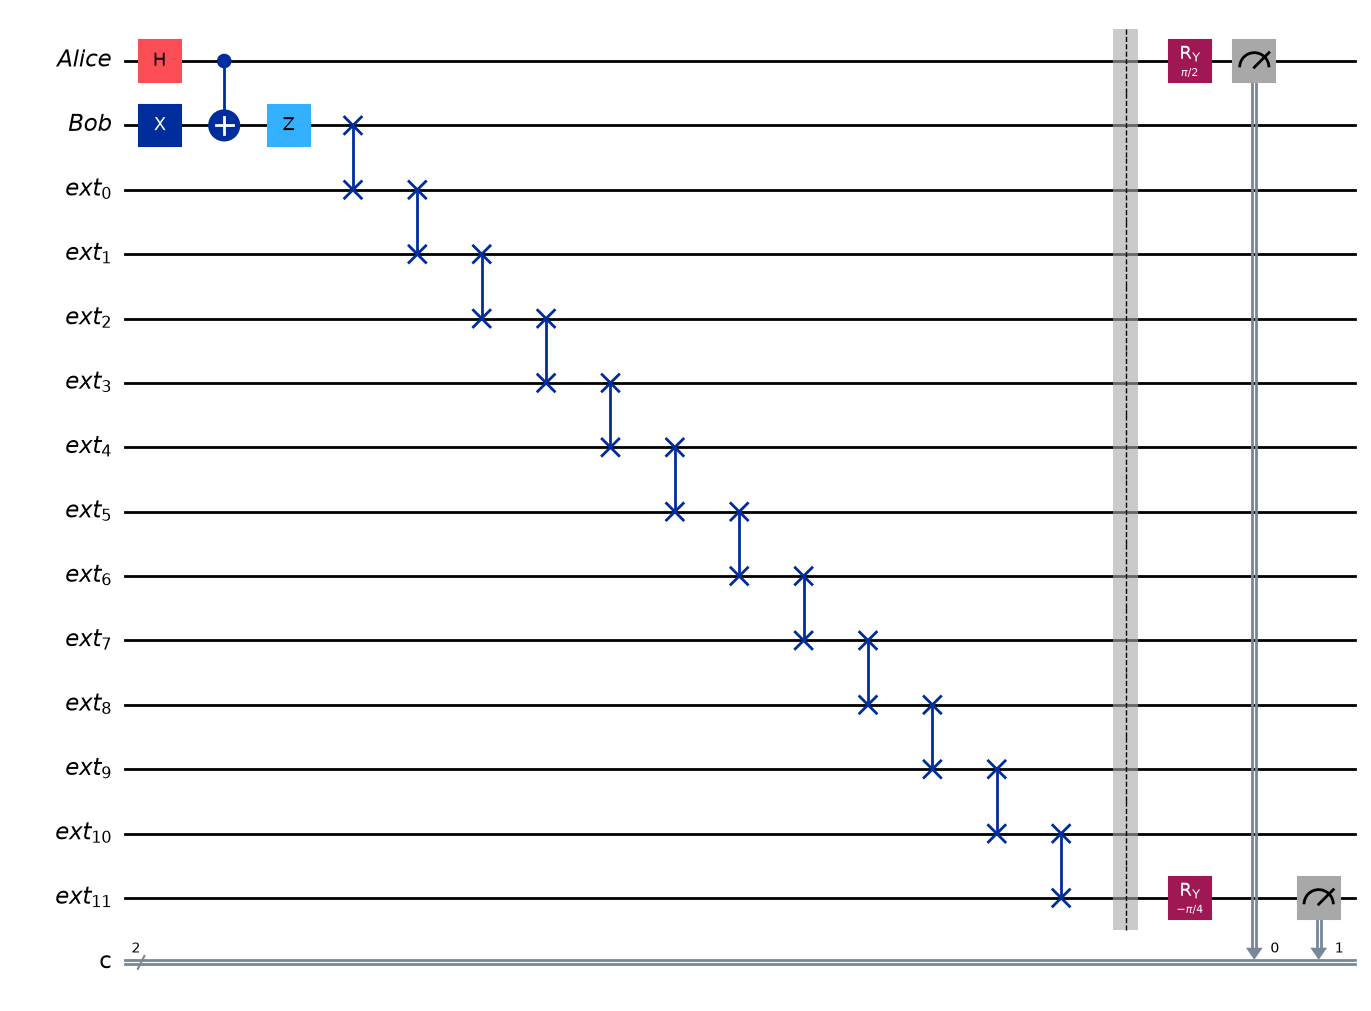

In [ ]:
# Número máximo de SWAPs
n_swaps =13




Ex = bell_with_swaps(n_swaps, theta_a=-np.pi/2, theta_b=np.pi/4)
Ex.draw(output="mpl")  

# Criação do Backend

In [5]:
# --- Create noise model ---
noise_model = NoiseModel()

# ----------------------------------------------------------
# Parâmetros do hardware
# ----------------------------------------------------------

# Tempos de coerência (ns)
T1 = 146.91e3
T2 = 62.35e3

# Tempos efetivos das portas
gate_time_1q = 50
gate_time_2q = 200

# Erros efetivos
p1 = 0.01
p2 = 0.02

# --- Define errors ---
error_1q = depolarizing_error(p1, 1).compose(
    thermal_relaxation_error(T1, T2, gate_time_1q)
)

error_2q = depolarizing_error(p2, 2).compose(
    thermal_relaxation_error(T1, T2, gate_time_2q).expand(
        thermal_relaxation_error(T1, T2, gate_time_2q)
    )
)

noise_model.add_all_qubit_quantum_error(
    error_2q, ["cx", "swap"]
)

# --- Measurement error ---
meas_error = depolarizing_error(0.02, 1)
noise_model.add_all_qubit_quantum_error(meas_error, ["measure"])

# --- Backend ---
backend_comp = AerSimulator(noise_model=noise_model)

## Ângulo para máxima violação

In [6]:
angles = {
    'A0B0': (0,           np.pi/4),
    'A0B1': (0,          -np.pi/4),
    'A1B0': (np.pi/2,     np.pi/4),
    'A1B1': (np.pi/2,    -np.pi/4),
}

## Correlação

In [7]:
# 3) Correlação E a partir das contagens
def correlacao(counts):
    """
    Converte counts ('00','01','10','11') em E = ⟨A·B⟩, mapeando 0->+1, 1->-1.
    Reverte a string para ficar [Alice, Bob] = [bit0, bit1].
    """
    shots = sum(counts.values())
    if shots == 0:
        return 0.0
    E = 0.0
    for outcome, freq in counts.items():
        bits = outcome[::-1]  # agora bits[0]=Alice, bits[1]=Bob
        a = 1 if bits[0] == '0' else -1
        b = 1 if bits[1] == '0' else -1
        E += a * b * (freq / shots)
    return E

## Calcular o Parâmetro S de Bell

In [8]:
def calcular_S(results_por_setting):
    """
    results_por_setting: dict com chaves 'A0B0','A0B1','A1B0','A1B1' -> counts
    """
    E00 = correlacao(results_por_setting['A0B0'])
    E01 = correlacao(results_por_setting['A0B1'])
    E10 = correlacao(results_por_setting['A1B0'])
    E11 = correlacao(results_por_setting['A1B1'])
    return E00 + E01 + E10 - E11

## Definição para calcular o valor de S (CHSH) em função do número de SWAPs

In [9]:
def chsh_vs_swaps(num_swaps, backend_sim, shots=1500000):
    S_results = {}
    raw_counts = {}

    for n in range(num_swaps + 1):
        results = {}

        for label, (ta, tb) in angles.items():

            qc = bell_with_swaps(
                n,
                theta_a=ta,
                theta_b=tb
            )

            tqc = transpile(
                qc,
                backend_sim,
                optimization_level=0
            )

            job = backend_sim.run(
                tqc,
                shots=shots
            )

            counts = job.result().get_counts()

            results[label] = counts

        S_value = abs(calcular_S(results))

        S_results[n] = S_value
        raw_counts[n] = results

        print(
            f"SWAPs = {n:>2d} | S = {S_value:.3f}"
        )

    return S_results, raw_counts

## Amp

In [10]:
noise_model = NoiseModel()

T1 = 146.91e3
T2 = 62.35e3
gate_time = 200

# erro de 1 qubit
single_error = thermal_relaxation_error(T1, T2, gate_time)

# erro de 2 qubits (SWAP)
two_qubit_error = single_error.tensor(single_error)


noise_model.add_all_qubit_quantum_error(
    two_qubit_error, ["cx", "swap"]
)

meas_error = thermal_relaxation_error(T1, T2, gate_time)
noise_model.add_all_qubit_quantum_error(meas_error, ["measure"])

backend_amp = AerSimulator(noise_model=noise_model)

## Despolarizing

In [11]:
# --- Create noise model ---
noise_model = NoiseModel()

p2 = 0.02  

# erros
error_2q = depolarizing_error(p2, 2)

noise_model.add_all_qubit_quantum_error(error_2q, ["cx", "swap"])

# Measurement error
meas_error = depolarizing_error(0.02, 1)
noise_model.add_all_qubit_quantum_error(meas_error, ["measure"])

backend_desp = AerSimulator(noise_model=noise_model)

In [12]:
S_results_desp, raw_counts_desp = chsh_vs_swaps(
    num_swaps=13,
    backend_sim=backend_desp,
    shots=2000000
)
S_results_amp, raw_counts_amp = chsh_vs_swaps(
    num_swaps=13,
    backend_sim=backend_amp,
    shots=2000000
)
S_results_comp, raw_counts_comp = chsh_vs_swaps(
    num_swaps=13,
    backend_sim=backend_comp,
    shots=2000000
)

SWAPs =  0 | S = 2.660
SWAPs =  1 | S = 2.609
SWAPs =  2 | S = 2.556
SWAPs =  3 | S = 2.507
SWAPs =  4 | S = 2.455
SWAPs =  5 | S = 2.406
SWAPs =  6 | S = 2.357
SWAPs =  7 | S = 2.312
SWAPs =  8 | S = 2.264
SWAPs =  9 | S = 2.222
SWAPs = 10 | S = 2.176
SWAPs = 11 | S = 2.131
SWAPs = 12 | S = 2.090
SWAPs = 13 | S = 2.047
SWAPs =  0 | S = 2.808
SWAPs =  1 | S = 2.802
SWAPs =  2 | S = 2.795
SWAPs =  3 | S = 2.789
SWAPs =  4 | S = 2.782
SWAPs =  5 | S = 2.774
SWAPs =  6 | S = 2.768
SWAPs =  7 | S = 2.763
SWAPs =  8 | S = 2.758
SWAPs =  9 | S = 2.753
SWAPs = 10 | S = 2.745
SWAPs = 11 | S = 2.739
SWAPs = 12 | S = 2.731
SWAPs = 13 | S = 2.726
SWAPs =  0 | S = 2.650
SWAPs =  1 | S = 2.592
SWAPs =  2 | S = 2.534
SWAPs =  3 | S = 2.476
SWAPs =  4 | S = 2.423
SWAPs =  5 | S = 2.367
SWAPs =  6 | S = 2.316
SWAPs =  7 | S = 2.263
SWAPs =  8 | S = 2.216
SWAPs =  9 | S = 2.164
SWAPs = 10 | S = 2.117
SWAPs = 11 | S = 2.069
SWAPs = 12 | S = 2.025
SWAPs = 13 | S = 1.979


In [15]:
# =========================
# EIXO X
# =========================

n_range = np.arange(0, 14)

# =========================
# PARÂMETROS
# =========================

p = 0.02
T1 = 140e3       # ns
gate = 200         # ns

# =========================
# TEORIA
# =========================

p_N = 1 - (1 - p)**n_range

S_theory_desp = (
    2 * np.sqrt(2) * (1 - p_N)
)

gamma_N = 1 - np.exp(
    -n_range * gate / T1
)

S_theory_amp = (
    np.sqrt(2) *
    np.abs(3 * gamma_N - 2)
)

S_theory_comp = (
    np.sqrt(2) *
    np.abs(
        (1 - p_N) * (3 * gamma_N - 2)
        + p_N * gamma_N**2
    )
)

# =========================
# SIMULAÇÕES
# =========================

ns_desp = np.array(
    sorted(S_results_desp.keys())
)

S_sim_desp = np.array([
    S_results_desp[n]
    for n in ns_desp
])

ns_amp = np.array(
    sorted(S_results_amp.keys())
)

S_sim_amp = np.array([
    S_results_amp[n]
    for n in ns_amp
])

ns_comp = np.array(
    sorted(S_results_comp.keys())
)

S_sim_comp = np.array([
    S_results_comp[n]
    for n in ns_comp
])

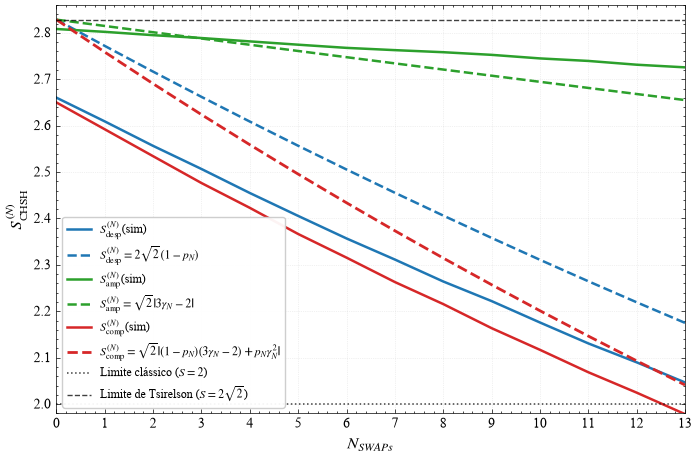

In [17]:
# ============================================================
# DADOS
# ============================================================

n_range = np.arange(0, 14)

# Parâmetros
p = 0.02
T1 = 62.35e3       # ns
gate = 200         # ns

# ============================================================
# RESULTADOS TEÓRICOS
# ============================================================

# -------------------------
# DEPOLARIZING
# -------------------------

p_N = 1 - (1 - p)**n_range

S_theory_desp = (
    2 * np.sqrt(2) * (1 - p_N)
)

# -------------------------
# AMPLITUDE DAMPING
# -------------------------

gamma_N = 1 - np.exp(
    -n_range * gate / T1
)

S_theory_amp = (
    np.sqrt(2) * np.abs(3 * gamma_N - 2)
)

# -------------------------
# COMPOSTO
# -------------------------

S_theory_comp = (
    np.sqrt(2) * np.abs(
        (1 - p_N) * (3 * gamma_N - 2)
        + p_N * gamma_N**2
    )
)

# ============================================================
# RESULTADOS NUMÉRICOS
# ============================================================

ns_desp = np.array(sorted(S_results_desp.keys()))
S_sim_desp = np.array([
    S_results_desp[n] for n in ns_desp
])

ns_amp = np.array(sorted(S_results_amp.keys()))
S_sim_amp = np.array([
    S_results_amp[n] for n in ns_amp
])

ns_comp = np.array(sorted(S_results_comp.keys()))
S_sim_comp = np.array([
    S_results_comp[n] for n in ns_comp
])

# ============================================================
# GRÁFICO
# ============================================================

with plt.style.context(["science", "no-latex"]):

    # --------------------------------------------------------
    # TIPOGRAFIA
    # --------------------------------------------------------

    plt.rcParams.update({
        "font.family": "Times New Roman",
        "mathtext.fontset": "stix",
        "font.size": 11,
        "axes.labelsize": 12,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "legend.fontsize": 8.5,
    })

    fig, ax = plt.subplots(figsize=(7.2, 4.8))

    # ========================================================
    # CORES
    # ========================================================

    color_desp = "#1f77b4"
    color_amp  = "#2ca02c"
    color_comp = "#d62728"

    # ========================================================
    # DEPOLARIZING
    # ========================================================

    ax.plot(
        ns_desp,
        S_sim_desp,
        "-",
        color=color_desp,
        linewidth=1.8,
        markersize=4.5,
        label=r"$S^{(N)}_{\mathrm{desp}}$(sim)"
    )

    ax.plot(
        n_range,
        S_theory_desp,
        "--",
        color=color_desp,
        linewidth=1.8,
        label=r"$S^{(N)}_{\mathrm{desp}}=2\sqrt{2}(1-p_N)$"
    )

    # ========================================================
    # AMPLITUDE DAMPING
    # ========================================================

    ax.plot(
        ns_amp,
        S_sim_amp,
        "-",
        color=color_amp,
        linewidth=1.8,
        markersize=4.5,
        label=r"$S^{(N)}_{\mathrm{amp}}$(sim)"
    )

    ax.plot(
        n_range,
        S_theory_amp,
        "--",
        color=color_amp,
        linewidth=1.8,
        label=r"$S^{(N)}_{\mathrm{amp}}=\sqrt{2}|3\gamma_N-2|$"
    )

    # ========================================================
    # COMPOSTO
    # ========================================================

    ax.plot(
        ns_comp,
        S_sim_comp,
        "-",
        color=color_comp,
        linewidth=1.8,
        markersize=4.8,
        label=r"$S^{(N)}_{\mathrm{comp}}$(sim)"
    )

    ax.plot(
        n_range,
        S_theory_comp,
        "--",
        color=color_comp,
        linewidth=2.0,
        label=(
            r"$S^{(N)}_{\mathrm{comp}}=\sqrt{2}"
            r"|(1-p_N)(3\gamma_N-2)+p_N\gamma_N^2|$"
        )
    )

    # ========================================================
    # LIMITE CLÁSSICO
    # ========================================================

    ax.axhline(
        2,
        linestyle=":",
        linewidth=1.1,
        color="black",
        alpha=0.75,
        label=r"Limite clássico ($S=2$)"
    )

    # ========================================================
    # LIMITE DE TSIRELSON
    # ========================================================

    ax.axhline(
        2 * np.sqrt(2),
        linestyle="--",
        linewidth=1.0,
        color="black",
        alpha=0.75,
        label=r"Limite de Tsirelson ($S=2\sqrt{2}$)"
    )

    # ========================================================
    # EIXOS
    # ========================================================

    ax.set_xlabel(
        r"$N_{SWAPs}$"
    )

    ax.set_ylabel(
        r"$S^{(N)}_{\mathrm{CHSH}}$"
    )

    ax.set_xlim(0, 12)
    ax.set_xticks(n_range)

    # Região relevante para S
    ax.set_ylim(1.98, 2.86)

    # ========================================================
    # GRID
    # ========================================================

    ax.grid(
        True,
        which="major",
        linestyle=":",
        linewidth=0.5,
        alpha=0.35
    )

    # ========================================================
    # LEGENDA
    # ========================================================

    ax.legend(
        loc="lower left",
        frameon=True,
        framealpha=0.95
    )

    # ========================================================
    # AJUSTE
    # ========================================================

    fig.tight_layout()
    
    fig.savefig(
        "chsh_vs_swaps.png",
        dpi=600,
        bbox_inches="tight"
    )

    plt.show()